Single allele groupped structue models.

In [167]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
import logomaker
import sys

PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"


 1. Read data

In [168]:
DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
# DATA_PATH_BASE = 'D:/Google Drive/Work/ITMO/data' #windows
# DATA_PATH_BASE = '/home/denklewer/Data' #ubuntu

DATA_PATH = f'{DATA_PATH_BASE}/length_dependent_hmm/per_length_per_kfold_split/' # work laptop
TARGET_PATH_TO_RESULTS = "experiment_results/properties_training_after_random_forest/" #!CHANGE for bwv!

In [169]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
# per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
# per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")

ALLELES

['HLA-A*11:01',
 'HLA-DRB1*03:01',
 'HLA-B*27:05',
 'HLA-B*07:02',
 'HLA-A*03:01',
 'HLA-A*02:01',
 'HLA-DRB3*01:01',
 'HLA-DRB5*01:01',
 'HLA-A*24:02',
 'HLA-DRB1*04:01',
 'HLA-DPA1*02:02/DPB1*05:01',
 'HLA-A*01:01',
 'HLA-DRB1*01:01',
 'HLA-DRB1*15:01',
 'HLA-DPA1*01:03/DPB1*04:01']

In [170]:
def make_logo_for_data(binders_array, name):
    sns.set_theme(style="white")
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True)
    ww_logo.ax.set_title(f"{name}, {len(binders_array)}")

# 2. Prepare data and weithgs for training
## 2.1 Merge alleles into combinations

In [171]:
# combination_size = len(ALLELES)
# ALLELES = sorted(['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'
#                   ])
#ALLELES = sorted([ 'HLA-B*07:02'])

# ALLELES = sorted(['HLA-DRB1*01:01', 'HLA-DPA1*01:03-DPB1*04:01'])
# ALLELES = sorted(['HLA-DRB1*01:01'])
ALLELES = sorted(['HLA-A*03:01'])


combination_size = 1
TOTAL_SPLITS = 5
NUM_RUNS = 5
USE_WEIGHTS = True
# TARGET_LENGTHS= [13, 14, 15, 16, 17, 18]
# TARGET_LENGTHS= [15]
TARGET_LENGTHS= [9]
check_peptides = False
multivariate = False

## Motif for train data

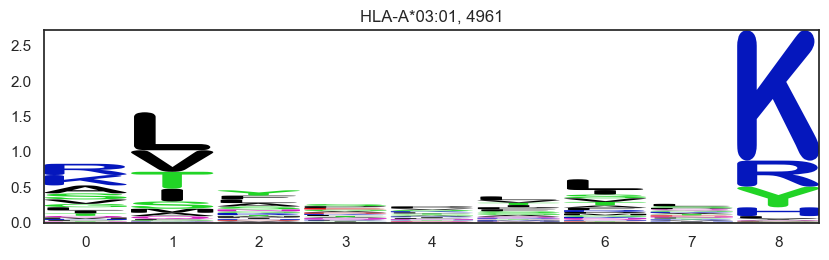

In [172]:
target_allele = ALLELES[0]
target_length = TARGET_LENGTHS[0]
peptides = per_allele_per_kfold_per_length_binders_train[target_allele][0][target_length]
make_logo_for_data(peptides, target_allele)

# Get initial params based on decoy data

In [173]:
from protlearn.features import aaindex1

In [174]:
## Select pre-saved properties
method_to_prop_file = {
    "DvB_RF" : "test/decoy_vs_binders_random_forest_important_properties.csv",
    "DvB_XB" : "test/decoy_vs_binders_xgboost_important_properties.csv",
    "DvB_RF_pos" : "test/per_position_decoy_vs_binders_random_forest_important_properties.csv",
    "DvB_XB_pos" : "test/per_position_decoy_vs_binders_xgboost_important_properties.csv",
    "BvN_RF" : "test/non_binders_vs_binders__random_forest_important_properties.csv",
    "BvN_XB" : "test/non_binders_vs_binders__xgboost_important_properties.csv",
    "BvN_RF_pos" : "test/per_position_non_binders_vs_binders__random_forest_important_properties.csv",
    "BvN_XB_pos" : "test/per_position_non_binders_vs_binders__xgboost_important_properties.csv",

}

METHOD = "DvB_RF"

In [175]:
amino_acids = list('ACDEFGHIKLMNPQRSTVWY')

# check intersection
for i, (method1, file1) in enumerate(method_to_prop_file.items()):
    for j, (method2, file2) in enumerate(method_to_prop_file.items()):
        if method1 != method2:
            if i < j:
                aa_prop_index1= pd.read_csv(file1, index_col=0)
                aa_prop_index2= pd.read_csv(file2, index_col=0)
                columns1 = set(aa_prop_index1.columns)
                columns2 = set(aa_prop_index2.columns)
                print(f"{method1} ({len(columns1)}) vs {method2} ({len(columns2)}) -- {len(columns1.intersection(columns2))}")

DvB_RF (63) vs DvB_XB (50) -- 49
DvB_RF (63) vs DvB_RF_pos (47) -- 47
DvB_RF (63) vs DvB_XB_pos (41) -- 40
DvB_RF (63) vs BvN_RF (59) -- 57
DvB_RF (63) vs BvN_XB (47) -- 47
DvB_RF (63) vs BvN_RF_pos (44) -- 42
DvB_RF (63) vs BvN_XB_pos (40) -- 39
DvB_XB (50) vs DvB_RF_pos (47) -- 39
DvB_XB (50) vs DvB_XB_pos (41) -- 37
DvB_XB (50) vs BvN_RF (59) -- 45
DvB_XB (50) vs BvN_XB (47) -- 35
DvB_XB (50) vs BvN_RF_pos (44) -- 33
DvB_XB (50) vs BvN_XB_pos (40) -- 31
DvB_RF_pos (47) vs DvB_XB_pos (41) -- 34
DvB_RF_pos (47) vs BvN_RF (59) -- 43
DvB_RF_pos (47) vs BvN_XB (47) -- 38
DvB_RF_pos (47) vs BvN_RF_pos (44) -- 37
DvB_RF_pos (47) vs BvN_XB_pos (40) -- 29
DvB_XB_pos (41) vs BvN_RF (59) -- 36
DvB_XB_pos (41) vs BvN_XB (47) -- 34
DvB_XB_pos (41) vs BvN_RF_pos (44) -- 32
DvB_XB_pos (41) vs BvN_XB_pos (40) -- 26
BvN_RF (59) vs BvN_XB (47) -- 41
BvN_RF (59) vs BvN_RF_pos (44) -- 38
BvN_RF (59) vs BvN_XB_pos (40) -- 39
BvN_XB (47) vs BvN_RF_pos (44) -- 38
BvN_XB (47) vs BvN_XB_pos (40) -- 29
BvN_R

In [176]:
import numpy as np
prop_values, prop_names = aaindex1(amino_acids, standardize='zscore')
# aa_prop_index = pd.DataFrame(prop_values, columns=prop_names, index=amino_acids).dropna(axis='columns')
aa_prop_index= pd.read_csv(method_to_prop_file[METHOD], index_col=0)

selected_properties= np.random.choice(aa_prop_index.columns, size=8 )
all_properties = list(aa_prop_index.columns)

In [177]:
aa_prop_index

,new_prop_0,new_prop_1,new_prop_10,new_prop_11,new_prop_13,new_prop_14,new_prop_15,new_prop_17,new_prop_18,new_prop_19,...,new_prop_66,new_prop_67,new_prop_68,new_prop_69,new_prop_7,new_prop_70,new_prop_71,new_prop_72,new_prop_8,new_prop_9
A,-1.429296,-0.274430,-0.507977,-0.631803,-0.639830,-0.344438,0.975058,-0.316156,1.226047,-0.274235,...,-0.402931,0.076632,0.635567,-0.118064,-0.285351,-0.591551,0.206572,-1.209077,0.434652,-0.547908
C,-0.165978,0.840132,0.019171,2.512809,-0.675887,-0.336458,-1.023467,-0.429775,-1.401087,-2.051392,...,1.022202,-0.513179,1.673172,-2.479967,1.051578,0.026079,-0.614947,0.503404,-0.427133,-0.766460
D,-0.478462,-1.061168,1.165839,1.031835,2.109296,1.125434,-0.656847,-0.139322,0.255858,0.724613,...,1.435701,0.506343,-1.102858,-0.630299,-0.294963,1.565869,-1.919359,-0.256526,1.766860,-0.589097
E,0.107572,-0.768375,-0.135773,0.273720,-0.515930,0.953682,-0.609046,0.224724,0.613036,-0.618819,...,-0.655170,-0.195933,0.455644,0.511617,0.603056,0.628942,-0.648784,-1.250244,2.625648,-0.855890
F,0.633390,1.050927,-0.741849,-0.395634,-0.364222,-1.293365,0.470729,0.513040,-0.569138,0.747019,...,0.985941,-1.051481,-0.324255,0.713757,0.759017,-0.017638,0.723445,-0.210342,-0.381880,2.101111
G,-1.732990,-0.323625,1.302845,-0.788608,-1.077854,0.606705,0.578743,-2.398285,1.277685,1.752532,...,-2.086082,0.804745,-1.396476,-1.322082,-0.201788,0.141732,-1.093035,0.463100,-0.593777,-0.266577
H,0.740862,0.247579,0.017841,0.416462,0.429638,0.871008,-0.932334,0.130390,-1.319949,-0.214487,...,0.845141,-0.448381,-0.023382,0.435072,-1.573553,-0.908554,-0.812695,0.579846,-0.408477,-0.154767
I,-0.113714,0.963791,-1.152906,-0.450921,0.614983,-1.287492,1.289434,1.015671,0.131350,-0.183541,...,-1.509504,-0.530900,-0.242521,-0.477215,1.778647,0.328777,1.689327,0.581464,-0.581699,1.354926
K,1.109553,-1.290673,0.138280,-0.883879,-0.122792,0.286193,-0.670793,0.652978,0.590381,0.209001,...,-0.360891,0.175912,0.677848,-0.206652,-0.808479,-0.405093,0.927217,-0.562186,-0.344986,-0.761515
L,-0.229879,1.354582,-1.080610,-0.591071,-0.078248,-1.108053,2.674398,1.429638,1.628260,-1.124324,...,-0.675164,-0.474695,0.285157,0.713921,0.395401,-1.235779,1.593334,-0.380958,-0.495099,-0.104469


In [178]:
transform_dicts = list()
name_to_dict = dict()

# We want to normalize values of properties
for property_name in selected_properties:
    transform_dicts.append(aa_prop_index[property_name].to_dict())
    name_to_dict[property_name] = aa_prop_index[property_name].to_dict()


In [179]:
len(transform_dicts)

8

In [180]:
transform_dicts = transform_dicts[0:3]

## Get decoy data

In [181]:
from mhcgnomes import parse
# decoy data
def defineOrganism(allele_name):
    parse_result = parse(allele_name)
    if parse_result.is_mouse:
        return "Mouse"
    elif parse_result.is_human:
        return "Human"
    else:
        print("organism not found")
        return None

def defineClass(allele_name):
    parse_result = parse(allele_name)
    if parse_result.has_mhc_class:
        if parse_result.is_class1:
            return 'I'
        elif parse_result.is_class2:
            return 'II'
        else:
            print("Not class I or class II???!")
    else:
        print("Result without class")
    return None

per_allele_decoy_peptides = dict()
for allele_name in ALLELES:
    organism =  defineOrganism(allele_name).lower()
    class_to_use = defineClass(allele_name)
    DECOY_DATA_PATH = f"{DATA_PATH_BASE}\decoy\sampled_decoy_data_{organism}_class_{class_to_use}.csv"
    decoy_df =  pd.read_csv(DECOY_DATA_PATH)
    decoy_df['length'] = decoy_df['peptide'].str.len()
    per_allele_decoy_peptides[allele_name] = decoy_df.copy()[decoy_df['length'].isin(TARGET_LENGTHS)]['peptide'].values

peptides_for_analysis = np.unique(np.concatenate([value for key, value in per_allele_decoy_peptides.items()
                                                  if key in ALLELES]))

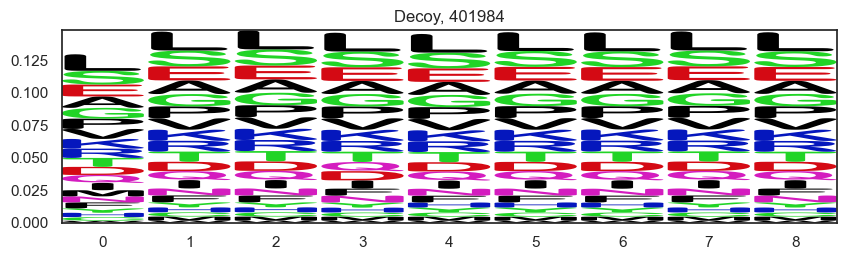

In [182]:
make_logo_for_data(peptides_for_analysis, "Decoy")

In [183]:
from tqdm import tqdm
from pomegranate.distributions import MultivariateGaussianDistribution
initial_params = list()
for transform_dict in tqdm(transform_dicts):
    decoy_converted = [transform_dict[aa] for peptide in peptides_for_analysis for aa in peptide]

    if not multivariate:
        mean_value = np.mean(decoy_converted)
        std_value = np.std(decoy_converted)
        initial_params.append({"mean": mean_value,
                               "std": std_value})
if multivariate:
    peptides_for_analysis = np.random.choice(peptides_for_analysis, 50)
    converted_decoy = np.array([[transform_dict[peptide[0]] for transform_dict in transform_dicts[:8]] for peptide in peptides_for_analysis])
    d7 = MultivariateGaussianDistribution.blank(converted_decoy.shape[1])
    d7.fit(converted_decoy)
    mean_value = d7.mu
    # std_value = d7.cov
    std_value = np.eye(converted_decoy.shape[1])
    initial_params.append({"mean": mean_value,
                           "std": std_value})

del decoy_converted

100%|███████████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:01<00:00,  2.05it/s]


In [184]:
initial_params

[{'mean': -0.02347836383502092, 'std': 0.8262429586236623},
 {'mean': -0.1264200854238813, 'std': 0.7405325256820686},
 {'mean': 0.20533383147858586, 'std': 0.9058552600280537}]

# Transform data

In [185]:
from data_reading_methods import merge_per_allele_sets_into_combination_sets

per_allele_per_kfold_per_length_binders_train_old = per_allele_per_kfold_per_length_binders_train
per_allele_per_kfold_per_length_binders_test_old = per_allele_per_kfold_per_length_binders_test


if check_peptides:
    transform_dicts=None

per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test = merge_per_allele_sets_into_combination_sets(
    per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test,
    combination_size=combination_size,
    selected_alelles=ALLELES,
    total_splits=TOTAL_SPLITS,
    list_of_transform_dicts=transform_dicts
)
OLD_ALLELES = ALLELES
NEW_ALLELES = list(per_allele_per_kfold_per_length_binders_test.keys())
ALLELES = NEW_ALLELES

HLA-A*03:01
Length 8: HLA-A*03:01 - 114 
Length 9: HLA-A*03:01 - 4961 
Length 10: HLA-A*03:01 - 2224 
Length 11: HLA-A*03:01 - 862 
Length 12: HLA-A*03:01 - 245 
Length 13: HLA-A*03:01 - 124 
Length 14: HLA-A*03:01 - 35 
Length 15: HLA-A*03:01 - 16 
Length 16: HLA-A*03:01 - 12 
Length 17: HLA-A*03:01 - 5 
Length 18: HLA-A*03:01 - 4 


In [186]:
ALLELES

['HLA-A*03:01']

In [187]:
per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][9]

array([[[-0.10133521, -0.52453259,  1.37069815],
        [-1.69170001, -0.02721564, -0.34909403],
        [-0.75039873, -0.58634456, -0.59967399],
        ...,
        [-0.10133521, -0.52453259,  1.37069815],
        [ 1.34640939,  0.82278838,  0.67303071],
        [ 0.62631105, -0.18694847, -1.37341763]],

       [[ 0.83135699, -0.40215841,  1.64108302],
        [-1.69170001, -0.02721564, -0.34909403],
        [ 2.12787233, -0.58384951,  0.31221279],
        ...,
        [ 0.22194522, -0.35232036, -0.14633751],
        [-0.75039873, -0.58634456, -0.59967399],
        [ 0.62631105, -0.18694847, -1.37341763]],

       [[ 0.22194522, -0.35232036, -0.14633751],
        [ 0.30141892,  0.09282479, -0.19207541],
        [-0.10133521, -0.52453259,  1.37069815],
        ...,
        [-0.10133521, -0.52453259,  1.37069815],
        [ 0.62631105, -0.18694847, -1.37341763],
        [ 0.62631105, -0.18694847, -1.37341763]],

       ...,

       [[ 0.83135699, -0.40215841,  1.64108302],
        [ 0

## 2.2 Calculate counts of initial data (will be used to calculate weights further)

In [188]:
from data_reading_methods import extract_count_df, calculate_weights_based_on_length_counts

count_df_train = extract_count_df(per_allele_per_kfold_per_length_binders_train_old,
                                  selected_alleles=OLD_ALLELES,
                                  total_splits=TOTAL_SPLITS)
count_df_test = extract_count_df(per_allele_per_kfold_per_length_binders_test_old,
                                 selected_alleles=OLD_ALLELES,
                                 total_splits=TOTAL_SPLITS)


In [189]:
count_df_train.index.levels

FrozenList([['HLA-A*03:01'], [0, 1, 2, 3, 4], [8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]])

## 2.3 Weights for data based on counts

In [190]:
per_allele_per_kfold_per_length_weights = calculate_weights_based_on_length_counts(count_df_train,
                                                                                   selected_alleles=ALLELES,
                                                                                   total_splits=TOTAL_SPLITS,
                                                                                   selected_lengths=TARGET_LENGTHS,
                                                                                   use_weights=USE_WEIGHTS)

Total data length for split 0 is 4961
Weights for lentgh 9 are {'HLA-A*03:01': 1.0}
Total data length for split 1 is 4961
Weights for lentgh 9 are {'HLA-A*03:01': 1.0}
Total data length for split 2 is 4961
Weights for lentgh 9 are {'HLA-A*03:01': 0.9997984683595325}
Total data length for split 3 is 4961
Weights for lentgh 9 are {'HLA-A*03:01': 0.9997984683595325}
Total data length for split 4 is 4961
Weights for lentgh 9 are {'HLA-A*03:01': 0.9997984683595325}


## Transform to properties

# 2. Train HMMS
## 2.1 Code for HMM
### 2.1.1 Training code

In [191]:
from hmm_logic_methods import train_model, save_model, add_more_states_and_reset_transitions, init_grouped_structure_model_joiners_and_cycles



## 2.2 Train
### 2.2.1 Define treshold

In [192]:
stop_threshold = 0
cutoff = 0.00005
per_symbol_portion = -5
for target_length in TARGET_LENGTHS:
    target_length_for_training = target_length
    train_size = len(per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length])
    ## Stop threshold Hardcoded here
    stop_threshold +=  abs(cutoff * train_size * per_symbol_portion  * target_length_for_training)
stop_threshold = stop_threshold / len(TARGET_LENGTHS)
stop_threshold

11.16225

### 2.2.2 Prepare  initial grouped structure models

In [193]:
# Training params
algorithm = 'baum-welch'

params = dict()


# params['st'] = 7
# params['multiple_check_input'] = False
# params['alg'] = algorithm
# params['min_iters'] = 30
# params['max_iters'] = 65
# params['stop_threshold'] = stop_threshold
# params['emission_pseudocount'] = 1
# params['transition_pseudocount'] = 0
# params['verbose'] = True
# params['lr_decay'] = 0
# params['edge_inertia'] = 0.25
# params['distribution_inertia'] = 0
# params['groups'] = 7
# params['states_per_group'] = 1
# params['use_pseudocount'] = True

params['st'] = 7
params['multiple_check_input'] = False
params['alg'] = algorithm
params['min_iters'] = 30
params['max_iters'] = 65
params['stop_threshold'] = stop_threshold
params['emission_pseudocount'] = 0
params['transition_pseudocount'] = 0
params['verbose'] = True
params['lr_decay'] = 0
params['edge_inertia'] = 0.25
params['distribution_inertia'] = 0.25
params['groups'] = 7
params['states_per_group'] = 1
params['use_pseudocount'] = False
# Class 1 params
params['self_cycle'] = True
params['start_cycle'] = False
params['end_cycle'] = False

params['freeze_distr'] = True # wether to freeze start and end cycle distributions
params['cycle_pseudocount'] = 1



assert params['st'] % params['groups'] == 0
assert params['st'] % params['states_per_group'] == 0
assert params['st'] == params['groups'] *  params['states_per_group']

params_for_string = {key: value for key, value in params.items() if key in ['st', 'alg', 'min_iters']}
params_string = "-".join([f"{value}-{key}" for key, value in params_for_string.items()])
lengths_string = "-".join(map(str, TARGET_LENGTHS))



In [194]:

from pomegranate import *
import json
import numpy as np
import pandas as pd
from pomegranate.io import BatchedDataGenerator, SequenceGenerator
from hmm_visualization_methods import convert_graph_to_good_format
import networkx as nx
from tqdm import tqdm
from collections import defaultdict
from pomegranate import IndependentComponentsDistribution

MINUS_INF_CONSTANT = -20
MINUS_INF_CONSTANT_NORMALIZED = -0.5

def init_distribution(amino_acids=None, initial_means=None, initial_stds=None, discrete_distribution=False, multivariate=False):
    amino_acids_list = list(amino_acids)
    if not discrete_distribution:
        if not multivariate:
            components_d  = list()
            for i in range(len(initial_params)):
                mean_value = initial_means[i]
                std_value = initial_stds[i]
                d = NormalDistribution(mean_value, std_value)
                components_d.append(d)
            total_d = IndependentComponentsDistribution(components_d)
        else:
            total_d = MultivariateGaussianDistribution(means=initial_means[0], covariance=initial_stds[0])
    else:
        d_dict = {key: prob for key, prob in zip(amino_acids_list, np.random.default_rng().uniform(0, 1, size=len(amino_acids_list)))}
        d_sum = sum(d_dict.values())
        d_dict = {key: value/d_sum for key, value in d_dict.items()}
        total_d = DiscreteDistribution(d_dict)
    return total_d


def init_grouped_structure_model_joiners_and_cycles_here(
        states_per_group=5, # may be int or list of numbers for each group
        number_of_groups=5,
        amino_acids="ACDEFGHIKLMNPQRSTVWY",
        freeze_distr=False,
        CYCLE_PSEUDOCOUNT=1,
        initial_params=None,
        start_cycle=True,
        end_cycle=True,
        self_cycles=False,
        discrete_distribution=False,
        multivariate=False
):

    INTRAGROUP_WEIGHT = 1
    INTERGROUP_WEIGHT = 1

    START_WEIGHT = 1
    TO_CYCLE_WEIGHT = 3
    IN_CYCLE_WEIGHT = 5
    if start_cycle or end_cycle:
        TO_JOINER_WEIGHT = 5 #just to make transitions even inside groups
    else:
        TO_JOINER_WEIGHT = 1
    END_WEIGHT = 1
    FROM_CYCLE_WEIGHT = 1
    amino_acids_list = list(amino_acids)

    joiner_positions = {0: [0], 1: [1]}
    number_of_joiners = sum(len(positions) for positions in joiner_positions.values())
    number_of_groups = number_of_groups

    if type(states_per_group) == list:
        assert number_of_groups == len(states_per_group), f"Number of groups is expected to be {number_of_groups} but got {len(states_per_group)} in a list of states per group"
    else:
        states_per_group = [states_per_group for i in range(number_of_groups)]
    distributions = list()


    mean_values = list()
    stds = list()
    for initial_distr_params in initial_params:
        mean_values.append(initial_distr_params['mean'])
        stds.append(initial_distr_params['std'])
    print(f"mean values : {mean_values}")
    print(f"std values : {stds}")

    # initialize group states
    for group_number in range(number_of_groups):
        states_in_group = states_per_group[group_number]
        for state_num in range(states_in_group):
            total_d = init_distribution(amino_acids=amino_acids,
                                        initial_means=mean_values,
                                        initial_stds=stds,
                                        discrete_distribution=discrete_distribution, multivariate=multivariate)
            distributions.append(total_d)
    #initialize joiner states (random here)
    joiner_label_to_index_in_model = dict()
    for joiner_name in range(number_of_joiners):
        # d = DiscreteDistribution(
        #     {key: prob for key, prob in zip(amino_acids_list, np.random.uniform(0, 1, size=len(amino_acids_list)))})
        total_d = init_distribution(amino_acids=amino_acids,
                                    initial_means=mean_values,
                                    initial_stds=stds,
                                    discrete_distribution=discrete_distribution, multivariate=multivariate)
        joiner_label_to_index_in_model[joiner_name] = len(distributions)
        distributions.append(total_d)
    # initialize cycle states
    if start_cycle:
        start_d = init_distribution(amino_acids=amino_acids,
                                    initial_means=mean_values,
                                    initial_stds=stds,
                                    discrete_distribution=discrete_distribution, multivariate=multivariate)
        if freeze_distr:
            start_d.freeze()
        distributions.append(start_d)
    if end_cycle:
        end_d = init_distribution(amino_acids=amino_acids,
                                  initial_means=mean_values,
                                    initial_stds=stds,
                                    discrete_distribution=discrete_distribution,multivariate=multivariate)
        if freeze_distr:
            end_d.freeze()
        distributions.append(end_d)


    # print("joiners positions", joiner_label_to_index_in_model)

    num_states = sum(states_per_group) + number_of_joiners +  int(start_cycle) + int(end_cycle) # groups, joiners, 2 cycles
    assert num_states == len(distributions)
    print(f"states will be groups:{sum(states_per_group)} + joiners:{number_of_joiners} + start/end cycles:{ int(start_cycle) + int(end_cycle)}")

    state_names = ["s{:03d}".format(i) for i in range(num_states)]
    transition_matrix = numpy.zeros((num_states, num_states))

    # start probabilities
    first_joiners = set(joiner_label_to_index_in_model[label] for label in joiner_positions[0])
    last_joiners = set(joiner_label_to_index_in_model[label] for label in joiner_positions[max(joiner_positions.keys())])
    # connect start cycle to the first joiners
    start_cycle_idx = sum(states_per_group) + number_of_joiners
    end_cycle_idx = start_cycle_idx + 1

    # start only for first cycle and first joiner
    start_probabilities = [START_WEIGHT
                           if i == start_cycle_idx or i in first_joiners
                           else 0
                           for i in range(num_states)]


    # do not restrict ending in multiple states, so probs are equal to transitions inside

    end_probabilities = [END_WEIGHT
                         if i == end_cycle_idx or i in last_joiners
                         else 0
                         for i in range(num_states)]

    #  start cycle transitions
    if start_cycle:
        for joiner_idx in first_joiners:
            transition_matrix[start_cycle_idx][joiner_idx] = FROM_CYCLE_WEIGHT # from cycle to joiners
        transition_matrix[start_cycle_idx][start_cycle_idx] = IN_CYCLE_WEIGHT #cycle
        start_probabilities[start_cycle_idx] = TO_CYCLE_WEIGHT #from start to cycle

    # connect last joiners to last cycle
    if end_cycle:
        for joiner_idx in last_joiners:
            transition_matrix[joiner_idx][end_cycle_idx] = TO_CYCLE_WEIGHT
        transition_matrix[end_cycle_idx][end_cycle_idx] = IN_CYCLE_WEIGHT


    # Transitions inside groups
    for group_number in range(number_of_groups):
        states_in_group = states_per_group[group_number]
        for i in range(states_in_group):
            state_num_from = sum(states_per_group[:group_number]) + i
            # fill transitions inside each group with INTRAGROUP_WEIGHT
            for j in range(states_in_group):

                state_num_to =  sum(states_per_group[:group_number]) + j
                if state_num_from != state_num_to:
                    transition_matrix[state_num_from][state_num_to] = INTRAGROUP_WEIGHT
            if self_cycles:
                transition_matrix[state_num_from][state_num_from] = INTRAGROUP_WEIGHT
            # transition to next group
            if group_number != number_of_groups - 1:
                for j in range(states_in_group):
                    state_num_to = sum(states_per_group[:group_number+1]) + j
                    transition_matrix[state_num_from][state_num_to] = INTERGROUP_WEIGHT



    # connect first joiner to first group
    for joiner_index in first_joiners:
        group_number = 0
        state_num_from = joiner_index
        states_in_group =  states_per_group[group_number]
        for j in range(states_in_group):
            state_num_to = sum(states_per_group[:group_number]) + j
            transition_matrix[state_num_from][state_num_to] = INTERGROUP_WEIGHT

    # connect last group to the last joiner
    for joiner_index in last_joiners:
        group_number = number_of_groups -1
        state_num_to = joiner_index
        states_in_group =  states_per_group[group_number]
        for j in range(states_in_group):
            state_num_from = sum(states_per_group[:group_number]) + j
            transition_matrix[state_num_from][state_num_to] = TO_JOINER_WEIGHT
    model_name = 'grouped_model'


    # assert sum(start_probabilities) == len(joiner_positions[0])* START_WEIGHT + TO_CYCLE_WEIGHT, start_probabilities
    # assert sum(end_probabilities) ==  (len(joiner_positions[max(joiner_positions.keys())]) + 1)  * END_WEIGHT, end_probabilities + list(last_joiners)

    model = HiddenMarkovModel.from_matrix(
        name=model_name,
        transition_probabilities=transition_matrix,
        starts=start_probabilities,
        distributions=distributions,
        ends=end_probabilities,
        state_names=state_names,
        verbose=True)
    # Update created model with specific pseudocounts
    if start_cycle:
        model.add_transition(model.states[start_cycle_idx], model.states[start_cycle_idx], IN_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
        model.add_transition(model.start, model.states[start_cycle_idx], IN_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
        for joiner_idx in first_joiners:
            model.add_transition(model.states[start_cycle_idx], model.states[joiner_idx], IN_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
    if end_cycle:
        model.add_transition(model.states[end_cycle_idx], model.states[end_cycle_idx], IN_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
        model.add_transition(model.states[end_cycle_idx],model.end, IN_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
        for joiner_idx in last_joiners:
            model.add_transition(model.states[joiner_idx], model.states[end_cycle_idx], IN_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)


        # model.add_transition(model.states[end_cycle_idx], model.states[end_cycle_idx], IN_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)

    model.bake(verbose=True)
    return model

In [195]:

model = init_grouped_structure_model_joiners_and_cycles_here(
    states_per_group=int(params['states_per_group']),
    number_of_groups=params['groups'],
    freeze_distr= params['freeze_distr'],
    CYCLE_PSEUDOCOUNT=params['cycle_pseudocount'] ,
    initial_params=initial_params,
    start_cycle=params['start_cycle'],
    end_cycle=params['end_cycle'],
    self_cycles=params['self_cycle'],
    discrete_distribution=check_peptides,
multivariate=multivariate)


mean values : [-0.02347836383502092, -0.1264200854238813, 0.20533383147858586]
std values : [0.8262429586236623, 0.7405325256820686, 0.9058552600280537]
states will be groups:7 + joiners:2 + start/end cycles:0
grouped_model : s000 summed to 2.0, normalized to 1.0
grouped_model : s001 summed to 2.0, normalized to 1.0
grouped_model : s002 summed to 2.0, normalized to 1.0
grouped_model : s003 summed to 2.0, normalized to 1.0
grouped_model : s004 summed to 2.0, normalized to 1.0
grouped_model : s005 summed to 2.0, normalized to 1.0
grouped_model : s006 summed to 2.0, normalized to 1.0


In [196]:
with open('model.png', 'w+') as f:
    model.plot(file=f, crop_zero=True, rotation=90, rotate=90)

In [197]:
from hmm_visualization_methods import *
plot_distributions_for_states(model,"test/", horizontal=False, discrete=check_peptides, initial_params=initial_params)

In [198]:
make_pyviz_graph(model, "test/", precision=3)

Converting graph for model (grouped_model) (Delete zero edges)


<class 'pyvis.network.Network'> |N|=11 |E|=17

In [199]:
initial_params

[{'mean': -0.02347836383502092, 'std': 0.8262429586236623},
 {'mean': -0.1264200854238813, 'std': 0.7405325256820686},
 {'mean': 0.20533383147858586, 'std': 0.9058552600280537}]

In [99]:
## Plot distributions
# list_of_dists = model.states[0].distribution.parameters[0]
# fig, axes = plt.subplots(ncols=1, nrows=len(list_of_dists), figsize=(5, len(list_of_dists)* 3))
# for i, distr in enumerate(list_of_dists):
#
#     distr_params = distr.parameters
#     mean_value = distr_params[0]
#     std_value = distr_params[1]
#     x = np.linspace(mean_value-4*std_value, mean_value+4*std_value, 1000)
#     y= norm.pdf(x, loc=mean_value, scale=std_value)
#     axes[i].plot(x, y, 'r', lw=2, label=f'pdf')
#     axes[i].text(0.0, 0.75, f'{np.round(mean_value,3)}', fontsize=35, transform=axes[i].transAxes)
#     axes[i].text(0.7, 0.75, f'{np.round(std_value,3)}', fontsize=35, transform=axes[i].transAxes)
#     transform_dict = transform_dicts[i]
#     prob_dict = {aa: distr.probability(value) for aa, value in transform_dict.items()}
#     print(dict(sorted(prob_dict.items(), key=lambda item:item[1])[:5]))
#
# print(f"mean_value was {mean_value}")

In [100]:
# allele_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS])
# ten_mer = allele_peptides[12]
# print(ten_mer, len(ten_mer))
#prob, path = model.viterbi(ten_mer)
#print([item[0] for item in path])
# sixteen_mer = peptide_properties[8900]
# print(sixteen_mer, len(sixteen_mer))

In [101]:
#pd.DataFrame(model.forward(sixteen_mer))

In [102]:
#pd.DataFrame(model.forward_backward(sixteen_mer)[1])

In [103]:
#pd.DataFrame(model.forward_backward(ten_mer)[1])

In [104]:
#ten_mer

In [105]:
#state_sums = [sum(state.distribution.parameters[0].values()) for state in model.states[:-2]]
# assert np.isclose(sum(state_sums), len(state_sums))

## Prepare models

In [106]:
per_allele_per_run_per_split_prepared_models = dict()
for allele_name in ALLELES:
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
    per_allele_per_run_per_split_prepared_models[allele_name] = dict()
    for run_num in range(NUM_RUNS):
        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = dict()
        for split_num in range(TOTAL_SPLITS):
            # prepared_model  = init_grouped_structure_model(states_per_group=int(params['st']/params['groups']), number_of_groups=params['groups'])
            prepared_model = init_grouped_structure_model_joiners_and_cycles_here(
                states_per_group=int(params['states_per_group']),
                number_of_groups=params['groups'],
                CYCLE_PSEUDOCOUNT=params['cycle_pseudocount'],
                freeze_distr=params['freeze_distr'],
                initial_params=initial_params,
                start_cycle=params['start_cycle'],
                end_cycle=params['end_cycle'],
                self_cycles=params['self_cycle'],
                discrete_distribution=check_peptides, multivariate=multivariate
            )


            prepared_model.name = f'{run_num}_run-{lengths_string}-{params_string}_model-{target_allele_name}-{split_num}'
            per_allele_per_run_per_split_prepared_models[allele_name][run_num][split_num] = prepared_model

mean values : [0.029758975333962503]
std values : [0.9628135468703809]
states will be groups:7 + joiners:2 + start/end cycles:0
grouped_model : s000 summed to 2.0, normalized to 1.0
grouped_model : s001 summed to 2.0, normalized to 1.0
grouped_model : s002 summed to 2.0, normalized to 1.0
grouped_model : s003 summed to 2.0, normalized to 1.0
grouped_model : s004 summed to 2.0, normalized to 1.0
grouped_model : s005 summed to 2.0, normalized to 1.0
grouped_model : s006 summed to 2.0, normalized to 1.0
mean values : [0.029758975333962503]
std values : [0.9628135468703809]
states will be groups:7 + joiners:2 + start/end cycles:0
grouped_model : s000 summed to 2.0, normalized to 1.0
grouped_model : s001 summed to 2.0, normalized to 1.0
grouped_model : s002 summed to 2.0, normalized to 1.0
grouped_model : s003 summed to 2.0, normalized to 1.0
grouped_model : s004 summed to 2.0, normalized to 1.0
grouped_model : s005 summed to 2.0, normalized to 1.0
grouped_model : s006 summed to 2.0, normal

In [107]:
# cycle_state = prepared_model.states[27]
# start = prepared_model.states[29]
# prepared_model.graph.edges()[cycle_state, cycle_state]

## Do training

In [108]:
%%time

per_name_models = dict()
per_allele_per_run_per_split_new_histories = dict()
for allele_name in ALLELES:
    per_allele_per_run_per_split_new_histories[allele_name] = dict()
    for run_num in range(NUM_RUNS):
        print(f"run {run_num}")
        per_kfold_per_length_data = per_allele_per_kfold_per_length_binders_train[allele_name]
        per_kfold_per_length_weights = per_allele_per_kfold_per_length_weights[allele_name]


        models, histories = train_model(allele_name=allele_name,
                                        per_kfold_per_length_data=per_kfold_per_length_data,
                                        per_kfold_per_length_weights_for_data=per_kfold_per_length_weights,
                                        target_lengths=TARGET_LENGTHS,
                                        multiple_check_input=params['multiple_check_input'],
                                        algorithm=params['alg'],
                                        verbose=params['verbose'],
                                        per_kfold_per_length_test_data=per_allele_per_kfold_per_length_binders_test[allele_name],
                                        stop_threshold=params['stop_threshold'],
                                        min_iterations= params['min_iters'],
                                        max_iterations=params['max_iters'],
                                        prepared_models=per_allele_per_run_per_split_prepared_models[allele_name][run_num],
                                        emission_pseudocount=params['emission_pseudocount'],
                                        transition_pseudocount=params['transition_pseudocount'],
                                        edge_inertia=params['edge_inertia'],
                                        distribution_inertia=params['distribution_inertia'],
                                        lr_decay=params['lr_decay'],
                                        use_pseudocount=params['use_pseudocount'])
        
        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = models
        per_allele_per_run_per_split_new_histories[allele_name][run_num] = histories
        # per_allele_per_run_per_split_models[allele_name][run_num] = models
        for split_num, model in models.items():
            per_name_models[model.name] = model
        # save models
        for split_num, model in models.items():
            history = histories[split_num]
            save_model(TARGET_PATH_TO_RESULTS, model,history)
        break



run 0
split 0
train size 4961
Shuffling for fairness 
Simple training: Train Length 4961, init_batch_size None
Use pseudocount is False
[1] Improvement: 28699.9140795407	Time (s): 0.3052
[2] Improvement: 4319.031823901889	Time (s): 0.3167
[3] Improvement: 879.1935350941058	Time (s): 0.2964
[4] Improvement: 207.54168597166426	Time (s): 0.3609
[5] Improvement: 51.123320459300885	Time (s): 0.2861
[6] Improvement: 12.733258961692627	Time (s): 0.289
[7] Improvement: 3.180342477695376	Time (s): 0.3136
[8] Improvement: 0.7948998677384225	Time (s): 0.3292
[9] Improvement: 0.198713357487577	Time (s): 0.356
[10] Improvement: 0.049677614093525335	Time (s): 0.3085
[11] Improvement: 0.012419357888575178	Time (s): 0.3168
[12] Improvement: 0.0031048366872710176	Time (s): 0.3692
[13] Improvement: 0.000776209169998765	Time (s): 0.3062
[14] Improvement: 0.0001940523216035217	Time (s): 0.2971
[15] Improvement: 4.8512971261516213e-05	Time (s): 0.2971
[16] Improvement: 1.2128279195167124e-05	Time (s): 0.29

In [109]:
from hmm_visualization_methods import *

In [110]:
%%time

for i, model in enumerate(per_name_models.values()):
    print(i)
    # with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph.png", 'w+') as f:
    #     model.plot(file=f, crop_zero=False)
    with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph_cropped.png", 'w+') as f:
        model.plot(file=f, crop_zero=True)

0
CPU times: total: 0 ns
Wall time: 56.7 ms


In [111]:
%%time

# for i, model in enumerate(per_name_models.values()):
#     plot_distributions_for_states(model,TARGET_PATH_TO_RESULTS, horizontal=False, discrete=check_peptides, initial_params=initial_params)
#     print(i)

CPU times: total: 0 ns
Wall time: 0 ns


In [112]:
# from hmm_visualization_methods import *
# per_name_pyviz = dict()
# for name, model in per_name_models.items():
#     per_name_pyviz[name] = make_pyviz_graph(model, TARGET_PATH_TO_RESULTS, precision=3)

## Check distrs

In [287]:
model = per_name_models[list(per_name_models.keys())[0]]

In [288]:
model.states[0]

{
    "class" : "State",
    "distribution" : {
        "class" : "Distribution",
        "name" : "MultivariateGaussianDistribution",
        "parameters" : [
            [
                -0.5003592816834495,
                0.7117140353332467,
                0.1520821408323309,
                -0.12639785271256618,
                -0.08985549501805185,
                0.38986971071636767,
                -0.3578281868911214,
                -0.20936321390608123
            ],
            [
                [
                    0.45429826447204036,
                    -0.035254398048458,
                    -0.16240158205446714,
                    -0.06069969334329286,
                    -0.002111960566620522,
                    -0.2916311750677875,
                    0.03632211178783991,
                    -0.1637582055594696
                ],
                [
                    -0.035254398048458,
                    0.2958527881503952,
                    0.00474186338893

## For given state select distributions that changed a lot

In [118]:
from collections import defaultdict
selected_state = model.states[1]
property_names = selected_properties

In [119]:
def bhattacharyya_gaussian_distance(mean1, cov1, mean2, cov2):
    """ Estimate Bhattacharyya Distance (between Gaussian Distributions)

    Args:
        distribution1: a sample gaussian distribution 1
        distribution2: a sample gaussian distribution 2

    Returns:
        Bhattacharyya distance
    """
    mean1 = np.array(mean1)
    mean2 = np.array(mean2)
    cov1 = np.array(cov1)
    cov2 = np.array(cov2)
    cov = (1 / 2) * (cov1 + cov2)

    T1 = (1 / 8) * (
        np.sqrt((mean1 - mean2) @ np.linalg.inv(cov) @ (mean1 - mean2).T)
    )
    T2 = (1 / 2) * np.log(
        np.linalg.det(cov) / np.sqrt(np.linalg.det(cov1) * np.linalg.det(cov2))
    )

    return T1 + T2

In [120]:
list_of_dists = selected_state.distribution.parameters[0]

property_to_distance = defaultdict(float)
property_to_distr = dict()
property_to_initial_distr = dict()
for i, distr in enumerate(list_of_dists):
    inital_param_distr = initial_params[i]
    initial_mean = inital_param_distr['mean']
    initial_std =  inital_param_distr['std']
    initial_distr = NormalDistribution(initial_mean, initial_std)
    distr_params = distr.parameters
    mean_value = distr_params[0]
    std_value = distr_params[1]
    distance = bhattacharyya_gaussian_distance([initial_mean], [[initial_std]], [mean_value], [[std_value]])
    property_to_distance[property_names[i]] = distance
    property_to_distr[property_names[i]] = distr
    property_to_initial_distr[property_names[i]] = initial_distr

TypeError: only size-1 arrays can be converted to Python scalars

In [121]:
selected_names = [name for name, distance in (sorted(property_to_distance.items(), key=lambda x:x[1], reverse=True))][:10]

In [122]:
transform_dicts

[{'A': 0.9144402031185958,
  'C': 0.6039207298648641,
  'D': -0.6740897272118904,
  'E': -0.946578475653672,
  'F': 0.7025328994092974,
  'G': 0.9128995868463206,
  'H': -0.6816466887262541,
  'I': 1.09699568752464,
  'K': -1.0113389653144018,
  'L': 1.020897432417324,
  'M': 0.522625957923501,
  'N': -0.8399480959075837,
  'P': 0.6149018427268865,
  'Q': -0.8318619034856745,
  'R': -2.5006442435577867,
  'S': -0.0843578316437353,
  'T': 0.0372778844774029,
  'V': 1.0724453684904232,
  'W': 0.1797434840010729,
  'Y': -0.1082151452993298},
 {'A': 0.5918806176922491,
  'C': -0.157016718363316,
  'D': 0.4028070104879587,
  'E': 0.5231168077331851,
  'F': -0.0865143427691986,
  'G': -0.1526637821083645,
  'H': -0.4342705288269207,
  'I': 0.4485036158328974,
  'K': 0.5095482291770587,
  'L': 0.4392942482962558,
  'M': 0.3071886013855525,
  'N': 0.0267047722662772,
  'P': -3.851634490102299,
  'Q': 0.4777774020273108,
  'R': 0.536870416982737,
  'S': 0.0717075494276899,
  'T': -0.17937964665

In [123]:
selected_distrs = [property_to_distr[name]  for name in  selected_names]


In [162]:
len(selected_distrs)

8

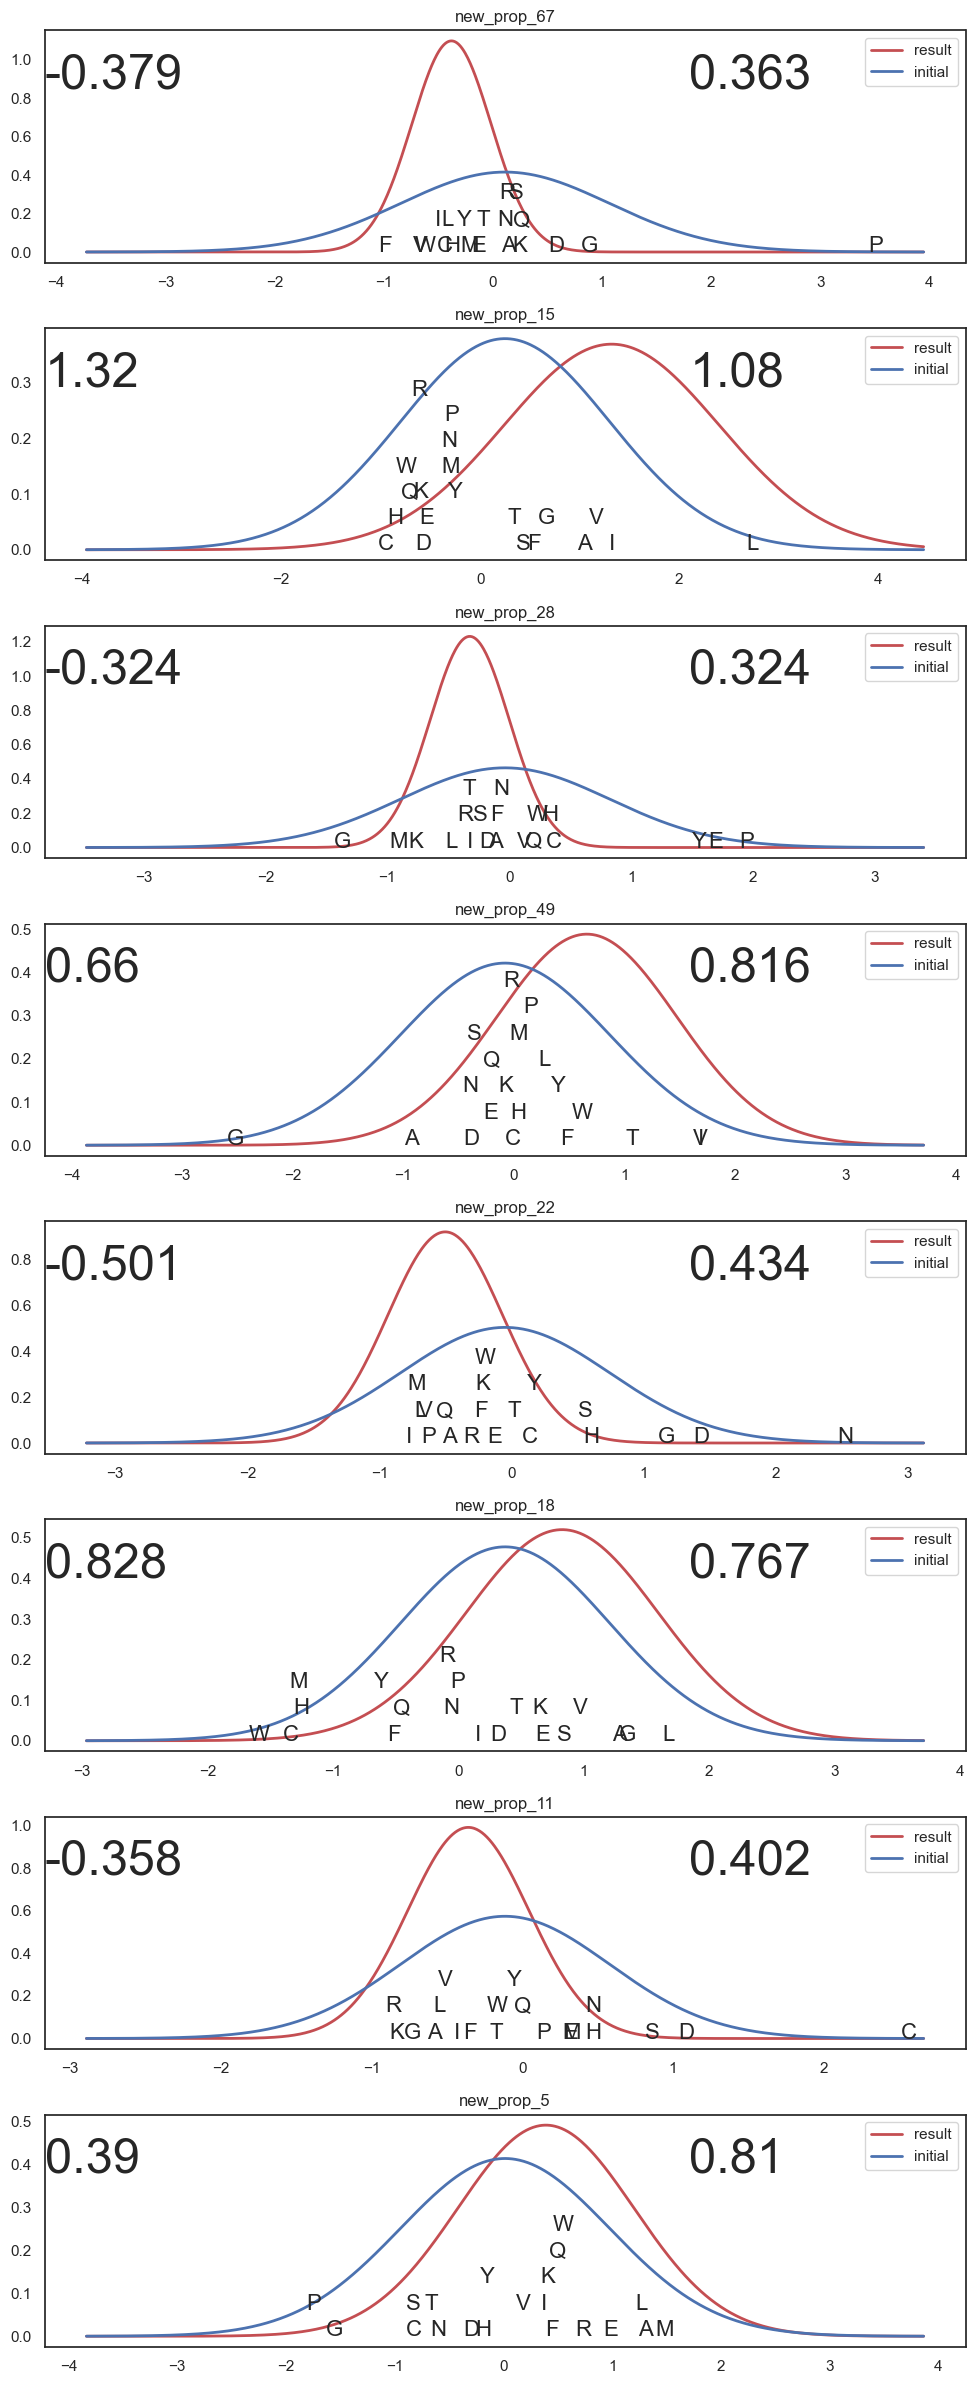

In [164]:
from collections import defaultdict
from scipy.stats import norm
# property_names = IMPORTANT_PROPERTIES_FROM_PAPER

list_of_dists = selected_distrs
property_names = selected_names
fig, axes = plt.subplots(ncols=1, nrows=len(list_of_dists), figsize=(10, len(list_of_dists)* 3))
for i, distr in enumerate(list_of_dists):
    ax = axes[i]
    property_name = selected_names[i]
    distr = property_to_distr[property_name]
    initial_distr = property_to_initial_distr[property_name]
    initial_mean = initial_distr.parameters[0]
    initial_std =  initial_distr.parameters[1]
    initial_distr = NormalDistribution(initial_mean, initial_std)
    distr_params = distr.parameters
    mean_value = distr_params[0]
    std_value = distr_params[1]
    x = np.linspace(initial_mean-4*initial_std, initial_mean+4*initial_std, 1000)
    y1= norm.pdf(x, loc=mean_value, scale=std_value)
    y2 = norm.pdf(x, loc=initial_mean, scale=initial_std)
    axes[i].plot(x, y1, 'r', lw=2, label=f'result')
    axes[i].plot(x, y2, 'b', lw=2, label=f'initial')
    axes[i].text(0.0, 0.75, f'{np.round(mean_value,3)}', fontsize=35, transform=ax.transAxes)
    axes[i].text(0.7, 0.75, f'{np.round(std_value,3)}', fontsize=35, transform=ax.transAxes)

    transform_dict =  name_to_dict[property_name]
    scale_value_y = max(y1)/8
    # print(f"scale {scale_value_y}")
    scale_value_x = std_value/3
    aa_to_x_position = dict()
    x_position_bin_to_aa = defaultdict(list)
    for aa,prop_value in transform_dict.items():
        aa_to_x_position[aa] = prop_value
    aa_to_y_position = dict()
    for aa,x_pos in aa_to_x_position.items():
        x_position_bin_to_aa[int(x_pos/scale_value_x)].append(aa)
    for bin, aas in x_position_bin_to_aa.items():
        for j, aa in enumerate(aas):
            aa_to_y_position[aa] = scale_value_y*j
    for aa,prop_value in transform_dict.items():
        ax.text(aa_to_x_position[aa], aa_to_y_position[aa], aa, fontsize=16 )

    # prob_dict = {aa: initial_distr.probability(value) for aa, value in transform_dict.items()}
    # print("before", dict(sorted(prob_dict.items(), key=lambda item:item[1],reverse=True)[:5]))
    # prob_dict = {aa: distr.probability(value) for aa, value in transform_dict.items()}
    # print("after", dict(sorted(prob_dict.items(), key=lambda item:item[1],reverse=True)[:5]))
    ax.legend()
    ax.set_title(property_name)
plt.tight_layout()

# Recover peptides from sampled vectors

In [289]:
model = per_name_models[list(per_name_models.keys())[0]]

per_aa_properties = defaultdict(list)

In [290]:
for transform_dict in transform_dicts:
    for aa, prop_value in transform_dict.items():
        per_aa_properties[aa].append(prop_value)


In [291]:
per_aa_properties = {aa: np.array(prop_vector) for aa, prop_vector in per_aa_properties.items()}

In [292]:
aa_vectors = pd.DataFrame(per_aa_properties).T
aa_vectors

,0,1,2,3,4,5,6,7
A,-0.591551,0.914440,0.635567,-1.841406,-0.592888,1.239569,-0.631803,-0.736055
C,0.026079,0.603921,1.673172,-0.241246,0.703220,-0.900565,2.512809,-1.215618
D,1.565869,-0.674090,-1.102858,0.319940,1.118873,-0.366156,1.031835,2.852956
E,0.628942,-0.946578,0.455644,0.401459,-0.548324,0.920453,0.273720,0.433118
F,-0.017638,0.702533,-0.324255,0.842916,-0.021865,0.379376,-0.395634,-0.219252
G,0.141732,0.912900,-1.396476,-2.983331,-0.987607,-1.633190,-0.788608,0.127129
H,-0.908554,-0.681647,-0.023382,0.616762,-0.795988,-0.255813,0.416462,-0.279760
I,0.328777,1.096996,-0.242521,-0.177081,1.138307,0.347415,-0.450921,-0.770367
K,-0.405093,-1.011339,0.677848,0.023453,-1.737179,0.339223,-0.883879,-0.812234
L,-1.235779,1.020897,0.285157,0.094155,0.122946,1.212728,-0.591071,-0.266956


In [293]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import Normalizer
# scaler = StandardScaler(with_std=True, with_mean=True)
# scaler.fit(aa_vectors)

In [294]:
peptide = model.sample()
peptide

array([[-2.35062025e-01, -4.77524576e-01,  2.26015302e-01,
        -1.08477855e+00, -2.15792634e+00, -3.07471660e-01,
        -8.10378356e-01, -7.46811169e-01],
       [ 1.14345036e+00,  1.55825420e+00, -3.91973999e-01,
        -4.12055782e-01, -3.76994882e-04, -5.67415071e-01,
        -8.64818387e-01, -1.66260164e+00],
       [-5.91623698e-01,  9.83072109e-01,  5.14806590e-02,
         4.47207278e-01,  3.48697069e-01,  8.82714164e-01,
        -1.08376532e+00, -2.60718403e-01],
       [-1.98112686e+00,  2.01768060e-01,  1.80381686e+00,
         1.91514974e-01, -7.25324155e-01,  2.08467468e+00,
        -8.63228574e-02, -8.36999341e-01],
       [-8.19267315e-01, -1.35399542e+00,  5.59436953e-01,
         9.59249719e-01,  2.43658557e-02,  4.40846088e-01,
         5.79868879e-02,  2.34242279e-02],
       [-6.97120911e-01, -1.13586557e-01,  5.32739573e-01,
        -5.44610171e-01, -1.39630119e+00, -2.94149842e-01,
        -2.67374361e-01,  7.78136237e-01],
       [ 7.77435758e-01,  9.194930

In [295]:
peptide, path = model.sample(path=True)
np.array(peptide)

C:\Users\denkl\AppData\Local\Temp\ipykernel_8788\3992593646.py:1: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  peptide, path = model.sample(path=True)


array([[-0.16407379, -0.01862196,  0.14500763, -0.6865842 , -1.15787414,
        -0.24158601, -0.23744903,  0.05877372],
       [ 0.40325296,  1.15401592, -0.26957119,  0.16740463,  1.03342964,
        -0.07340497, -0.50636687, -1.15197244],
       [-0.37427138, -0.05600302, -1.70757379,  0.85331958,  0.40105603,
         0.28893771, -1.15156345, -0.56299776],
       [-0.23858134,  0.29145344, -0.45773789, -1.20674175,  0.36729638,
        -1.07677604,  0.29231098,  0.63984142],
       [-1.40953718, -0.22816624, -0.10965315, -1.2163889 , -0.56102217,
         0.47230942,  0.03578249,  0.39770522],
       [-1.32908911,  0.34510145,  0.25598433,  0.18374199, -0.36232023,
         1.18711796, -0.3883673 , -0.91765714],
       [-1.3000196 ,  1.73473128,  0.33906163,  0.2565091 , -0.7122279 ,
        -0.14654039, -0.09487489, -0.72487753],
       [-0.57624108,  1.12534321, -0.15666418, -0.89386023, -0.11758214,
         0.86446233, -0.71232545, -0.41037166],
       [-0.59222958, -0.8093944 

In [296]:
[state.name for state in path]

['grouped_model-start',
 's007',
 's000',
 's001',
 's002',
 's003',
 's004',
 's005',
 's006',
 's008',
 'grouped_model-end']

In [297]:
from scipy.spatial import distance

recovered_peptide = list()
for sampled_prop_vector in peptide:
    distance_dict = dict()
    sampled_prop_vector = sampled_prop_vector
    # sampled_prop_vector = scaler.transform(sampled_prop_vector.reshape(1,-1)).reshape(-1)
    for aa, aa_prop_vector in per_aa_properties.items():

        # aa_prop_vector = scaler.transform(aa_prop_vector.reshape(1,-1)).reshape(-1)

        distance_dict[aa] = distance.euclidean(sampled_prop_vector, aa_prop_vector)
    aa = min(distance_dict.items(), key=lambda x:x[1])[0]
    recovered_peptide.append(aa)
    print(distance_dict)
    print(aa)

{'A': 2.434728352696761, 'C': 4.0054027575541395, 'D': 4.539849388990032, 'E': 2.212153440170875, 'F': 2.208963659230982, 'G': 3.299464432182638, 'H': 1.8423589614622502, 'I': 2.872227359397137, 'K': 1.9186215216474831, 'L': 2.616299935025868, 'M': 3.430060844281875, 'N': 1.8481106774429312, 'P': 4.565821278571946, 'Q': 2.0427239306011176, 'R': 3.0523391153105326, 'S': 1.6088066135471526, 'T': 1.3940578114823354, 'V': 1.9566079680491717, 'W': 3.4470823982041483, 'Y': 3.705470673020211}
T
{'A': 3.2340624968283183, 'C': 3.781378113932314, 'D': 4.889765264634324, 'E': 3.413926710661301, 'F': 1.7438979022396963, 'G': 4.4223130847427194, 'H': 3.216432103637128, 'I': 0.6818987767092036, 'K': 3.790116651265847, 'L': 2.508143358312861, 'M': 3.0030921429698276, 'N': 3.6274495494551955, 'P': 3.697336018513685, 'Q': 2.7846174200619314, 'R': 4.149040246060152, 'S': 3.6822599880502462, 'T': 3.3811597717165767, 'V': 1.6159360801813174, 'W': 2.4667461829579413, 'Y': 2.340300879289099}
I
{'A': 3.99156

##

In [298]:
selected_length = 9
sampled_peptides = model.sample(n=5000)

In [299]:
probs = pd.DataFrame({"index": [i for i in range(len(sampled_peptides))],"prob":[model.viterbi(peptide)[0]  for peptide in sampled_peptides]})
probs['len'] = [len(x) for x in sampled_peptides]
probs['norm_prob'] = probs['prob'] / probs['len']

probs = probs[probs.len == selected_length].sort_values(by='norm_prob', ascending=False)


In [300]:
probs.len.value_counts()

9    5000
Name: len, dtype: int64

In [301]:
""
sampled_peptides = np.array(sampled_peptides, dtype=object)
selected_peptides = sampled_peptides[probs.head(5000).index.values]

In [302]:
reverse_transformed_peptides = list()
for sampled_peptide in selected_peptides:
    recovered_peptide = list()
    for sampled_prop_vector in sampled_peptide:

        distance_dict = dict()

        # sampled_prop_vector = scaler.transform(sampled_prop_vector.reshape(1,-1)).reshape(-1)
        for aa, aa_prop_vector in per_aa_properties.items():
            # aa_prop_vector = scaler.transform(aa_prop_vector.reshape(1,-1)).reshape(-1)
            distance_dict[aa] = distance.cosine(sampled_prop_vector, aa_prop_vector)
        aa = min(distance_dict.items(), key=lambda x:x[1])[0]
        recovered_peptide.append(aa)
    reverse_transformed_peptides.append("".join(recovered_peptide))


C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T


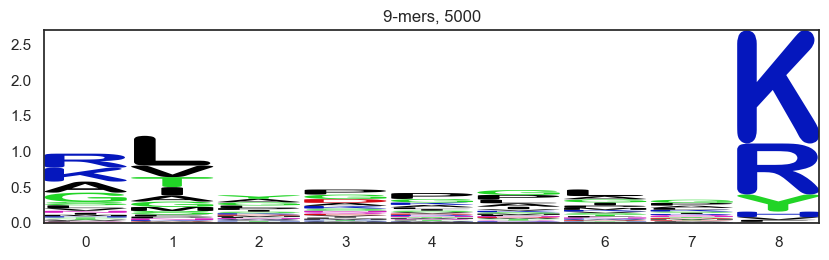

In [303]:
import logomaker
make_logo_for_data(reverse_transformed_peptides, f"{selected_length}-mers")

In [59]:
reverse_transformed_peptides

['RLYAPPLLK',
 'RLGDFLLKK',
 'ALYTPLIAK',
 'ALGGPVLVK',
 'RLLTDILSK',
 'KVAQPIATK',
 'LLRGTTVAK',
 'RIGAQVLPK',
 'KLYGPLLTK',
 'GLMAPPLGK',
 'AINTETLSK',
 'TIDEPVIPR',
 'RVFEPALVR',
 'KVMPPGLGK',
 'KVVSLILLK',
 'ALFDPGLLK',
 'KVYNVALKK',
 'KIYGQVIPK',
 'AVYTQKVQK',
 'TLPGYALKK',
 'ALFTPVIWK',
 'ALVPGALRK',
 'RLLVALATK',
 'VLLPRPVPK',
 'LLAPTLLVK',
 'LLHDTAIAK',
 'RLRDIVLGK',
 'QLQGGILSK',
 'AIAPGLLSK',
 'KVMGPLIPK',
 'RVISAIIRR',
 'KVGGSVLLK',
 'ALYPAGIIK',
 'SVAEGALGK',
 'VLFGPVLAK',
 'KLKANLLSK',
 'KVFLPPVLK',
 'HVRGPPVAK',
 'LLYDGLLKK',
 'RIGDRGLVK',
 'AIRGAILSK',
 'KVSPIALSK',
 'KLYSVILAK',
 'AVASIIFNK',
 'VIMGEIIGK',
 'ALFGAVLTK',
 'TVKSPVLLK',
 'AVLATLVAK',
 'RVADKSIAK',
 'SLFSSVGSK',
 'KLYKSLLSK',
 'KVMGAVLTK',
 'KLAQRLLMK',
 'SLLAPGLSK',
 'KVLDPELVK',
 'SLGGTWLVK',
 'RLSPPFLTK',
 'KLETTTLCK',
 'ALASGPISK',
 'RLIGPVFLK',
 'KLLAPLVTK',
 'AVLQAFLAK',
 'KLMAVTLNK',
 'RVASPALAK',
 'AVFEVKIAK',
 'VVYEVPLGK',
 'KLISPLIKK',
 'AVTAPVVLK',
 'KFLSPHVSK',
 'RIFPGILSK',
 'VLKAPAVRK',
 'RLMG

In [58]:
property = 2


transform_dict = transform_dicts[property].copy()
del transform_dict['-']
for sampled_peptide in model.sample(n=10000):
    peptide = []
    for sampled_value in sampled_peptide[:, property]:
        distance_dict = {key: abs(value - sampled_value) for key, value in transform_dict.items()}
        peptide.append(min(distance_dict, key=distance_dict.get))
    reverse_transformed_peptides.append("".join(peptide))

KeyError: '-'

In [ ]:
reverse_transformed_peptides

In [ ]:
df_reverse = pd.DataFrame({"peptide": reverse_transformed_peptides})

In [ ]:
df_reverse['len'] = df_reverse.peptide.str.len()

In [ ]:
df_reverse.len.value_counts()

In [ ]:
selected_length = 9
peptides_for_motif = df_reverse[df_reverse['len'] == selected_length]['peptide'].values

In [ ]:
peptides_for_motif[:10]

In [156]:
min(transform_dicts[0].items(), key=lambda (key, value) :abs(x-value))

SyntaxError: invalid syntax (Temp/ipykernel_12296/2630203387.py, line 1)

In [149]:
best_peptide

array([[  1.39630017, -16.55327495,  -0.50517585],
       [  0.62983504, -17.32035868,  -0.04732805],
       [  1.25262103, -15.27089694,   0.22294073],
       [  1.23978008, -12.11114207,  -0.73748807],
       [  1.11034866, -14.78909163,  -0.44471221],
       [  1.50580789, -12.86561112,   0.5618994 ],
       [  1.31368093, -12.06770185,  -0.24385359],
       [  1.15146528, -15.90527935,  -0.43256495],
       [  1.82034438, -12.18436169,   0.84763509],
       [  0.87271453, -16.55206062,  -0.02321879],
       [  1.17151958, -13.00875451,   0.67231885]])

In [143]:
train_peptide = correct_peptides_transformed[1]

In [148]:
correct_peptides[1]

'KLATSVLAGLLGVVS'

<AxesSubplot:>

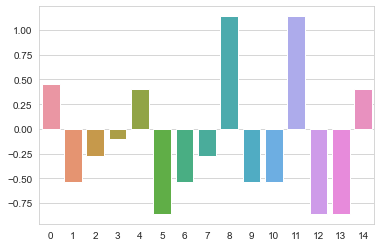

In [144]:
sns.barplot(x=np.arange(0, len(train_peptide)), y=train_peptide[:, 2])

<AxesSubplot:>

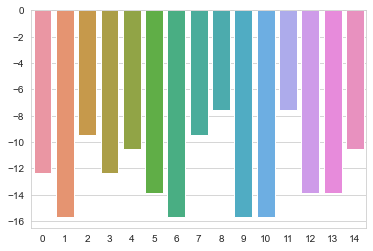

In [145]:
sns.barplot(x=np.arange(0, len(train_peptide)), y=train_peptide[:, 1])

<AxesSubplot:>

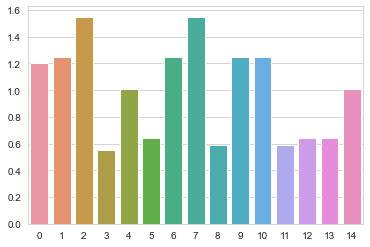

In [146]:
sns.barplot(x=np.arange(0, len(train_peptide)), y=train_peptide[:, 0])

In [69]:
np.sum(ten_best_peptides, axis=0)

ValueError: operands could not be broadcast together with shapes (11,3) (10,3) 

In [38]:
peptide

array([[  1.39125768, -18.21882837,   0.14343468],
       [  1.27708304, -12.11991018,  -0.12214817],
       [  0.67135385, -24.91573046,  -0.35113952],
       [  0.67629342, -13.39393235,  -0.75467282],
       [  0.84934097, -17.00151845,  -0.21059953],
       [  1.49461083, -15.80499407,  -0.49082834],
       [  2.40277322, -14.24836669,  -0.39752995],
       [  0.99209309, -10.05710951,   0.45446181],
       [  0.83780578, -17.49903151,  -0.5932868 ],
       [  0.9122496 , -13.12360981,   0.97000934],
       [  1.39638222, -12.20867203,   0.21481616],
       [  0.67551882, -15.88611363,  -0.49447582]])

In [43]:
allele_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS])

In [159]:
ALLELES

['HLA-DPA1*01:03-DPB1*04:01', 'HLA-DRB1*01:01']

In [189]:
peptide = allele_peptides[5]
peptide

'SEAYLVGLFEDTN'

In [395]:
result = model.sample(n=1000, path=True)

C:\Users\Denis\AppData\Local\Temp/ipykernel_524/1975844636.py:1: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  result = model.sample(n=1000, path=True)


In [401]:
max_prob = -2000
max_path = None
max_peptide = None
for peptide, path in result:
    prob, viterbi_path = model.viterbi(peptide)
    prob = prob / len(peptide)
    if prob > max_prob:
        max_prob = prob
        max_path = path
        max_peptide = peptide

In [402]:
max_prob

-4.51326669648934

In [403]:
np.array(max_peptide)

array([[  0.77854669, -13.48282057,  -0.12539222],
       [  0.68272319, -10.01034668,   0.45376615],
       [  1.11036063, -13.41180047,   0.07183059],
       [  1.43216508, -15.12568617,  -0.17483103],
       [  0.8247562 , -13.89272745,  -0.75090236],
       [  0.40071125, -10.18791148,   0.07350749],
       [  1.47000848, -10.31069451,  -0.02101558],
       [  1.21072014, -15.18928383,  -0.62101386],
       [  1.35362278, -13.5447453 ,  -0.17876816],
       [  0.48538224, -12.09842882,   0.861933  ],
       [  0.78798226, -11.34902157,   0.20948479],
       [  1.37750587, -18.45099161,  -0.49834661],
       [  1.08685715, -14.84568831,   0.63004817],
       [  1.08354241, -13.90456608,  -0.21236269]])

In [190]:
print([item[1].name for item in model.viterbi(peptide)[1]])

['grouped_model-start', 's027', 's027', 's025', 's004', 's005', 's008', 's012', 's016', 's017', 's021', 's022', 's026', 's028', 'grouped_model-end']


In [ ]:
NGFKTQHFV

In [50]:
model.graph.edges()[cycle_state, cycle_state]

{'probability': -1.2327600919633284, 'pseudocount': 8000, 'group': None}